# EN3160 Assignment 3 on Neural Networks

**Index No:** 230476T
**Name:** Perera G.M.B.

https://github.com/maneth-b03p/Image_Processing_and_Machine_Vision_Activities.git

## Question 1: Single Dense Layer Network on CIFAR-10

Epoch 1/10, Loss: 2.3025855255126952
Epoch 2/10, Loss: 2.302585482597351
Epoch 3/10, Loss: 2.302585424661636
Epoch 4/10, Loss: 2.302585391998291
Epoch 5/10, Loss: 2.3025853505134584
Epoch 6/10, Loss: 2.3025853297710417
Epoch 7/10, Loss: 2.3025852904319764
Epoch 8/10, Loss: 2.3025852811336516
Epoch 9/10, Loss: 2.3025852496623993
Epoch 10/10, Loss: 2.3025852229595185


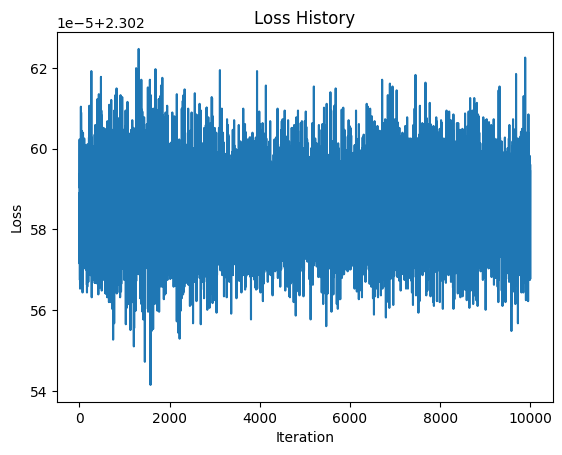

Training accuracy: 10.00%
Test accuracy: 10.00%


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', download=True,
                                        train=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', download=True,
                                       train=False, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'deer', 'dog', 'frog', 'cat', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
nodes = 100
K = 10  # Output size (number of classes in CIFAR-10)
std = 1e-5  # Initialize weights and biases
w1 = torch.randn(Din, nodes) * std
b1 = torch.zeros(nodes)

w2 = torch.randn(nodes, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 2e-6  # Learning rate
lr_decay = 0.9  # Learning rate decay
reg = 0  # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        a_0 = x_train.mm(w1) + b1
        a_1 = torch.sigmoid(a_0)
        z = a_1.mm(w2) + b2
        z_max = torch.max(z, dim=-1, keepdim=True).values
        y_pred = torch.exp(z-z_max)/torch.sum(torch.exp(z-z_max), dim=-1, keepdim=True)

        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(y_pred + 1e-15)) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dz = (1.0 / Ntr) * (y_pred - y_train_onehot)

        dw2 = a_1.t().mm(dz) + 2.0 * reg * w2
        db2 = dz.sum(dim=0)

        da_1 = dz.mm(w2.t())
        da_0 = da_1 * a_1 * (1.0 - a_1)

        dw1 = x_train.t().mm(da_0) + 2.0 * reg * w1
        db1 = da_0.sum(dim=0)

        # Parameter update
        w2 -= lr * dw2
        b2 -= lr * db2
        w1 -= lr * dw1
        b1 -= lr * db1

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        a_0 = x_train.mm(w1) + b1
        a_1 = torch.sigmoid(a_0)
        z = a_1.mm(w2) + b2
        z_max = torch.max(z, dim =-1, keepdim=True).values
        y_train_pred = torch.exp(z-z_max)/torch.sum(torch.exp(z-z_max), dim=-1, keepdim=True)

        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        a_0 = x_test.mm(w1) + b1
        a_1 = torch.sigmoid(a_0)
        z = a_1.mm(w2) + b2
        z_max = torch.max(z, dim = -1, keepdim=True).values
        y_test_pred = torch.exp(z-z_max)/torch.sum(torch.exp(z-z_max), dim = -1, keepdim=True)

        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Epoch 1/10, Loss: 2.00321379840374
Epoch 2/10, Loss: 1.755520158648491
Epoch 3/10, Loss: 1.6756386580467224
Epoch 4/10, Loss: 1.6194483194351197
Epoch 5/10, Loss: 1.5707591142654418
Epoch 6/10, Loss: 1.526695337176323
Epoch 7/10, Loss: 1.489023651242256
Epoch 8/10, Loss: 1.452306029677391
Epoch 9/10, Loss: 1.4196699784994125
Epoch 10/10, Loss: 1.390426461815834


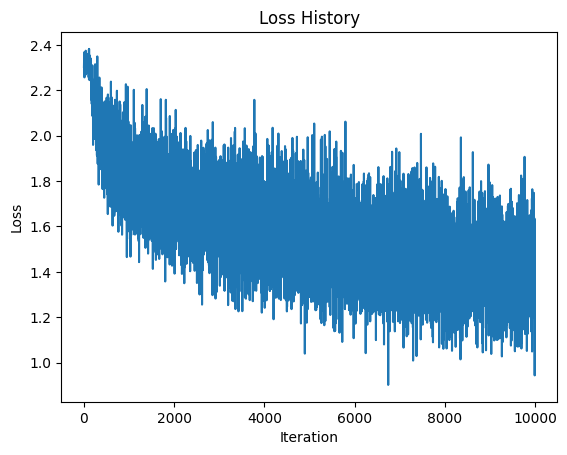

Training accuracy: 52.90%
Test accuracy: 47.67%


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', download=True,
                                        train=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', download=True,
                                       train=False, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'deer', 'dog', 'frog', 'cat', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
nodes = 100
K = 10  # Output size (number of classes in CIFAR-10)
std = 1e-5  # Initialize weights and biases
w1 = torch.randn(Din, nodes) * std
b1 = torch.zeros(nodes)

w2 = torch.randn(nodes, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 1.2e-1  # Learning rate
lr_decay = 0.95  # Learning rate decay
reg = 0  # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        a_0 = x_train.mm(w1) + b1
        a_1 = torch.sigmoid(a_0)
        z = a_1.mm(w2) + b2
        z_max = torch.max(z, dim=-1, keepdim=True).values
        y_pred = torch.exp(z-z_max)/torch.sum(torch.exp(z-z_max), dim=-1, keepdim=True)

        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(y_pred + 1e-15)) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dz = (1.0 / Ntr) * (y_pred - y_train_onehot)

        dw2 = a_1.t().mm(dz) + 2.0 * reg * w2
        db2 = dz.sum(dim=0)

        da_1 = dz.mm(w2.t())
        da_0 = da_1 * a_1 * (1.0 - a_1)

        dw1 = x_train.t().mm(da_0) + 2.0 * reg * w1
        db1 = da_0.sum(dim=0)

        # Parameter update
        w2 -= lr * dw2
        b2 -= lr * db2
        w1 -= lr * dw1
        b1 -= lr * db1

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        a_0 = x_train.mm(w1) + b1
        a_1 = torch.sigmoid(a_0)
        z = a_1.mm(w2) + b2
        z_max = torch.max(z, dim =-1, keepdim=True).values
        y_train_pred = torch.exp(z-z_max)/torch.sum(torch.exp(z-z_max), dim=-1, keepdim=True)

        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        a_0 = x_test.mm(w1) + b1
        a_1 = torch.sigmoid(a_0)
        z = a_1.mm(w2) + b2
        z_max = torch.max(z, dim = -1, keepdim=True).values
        y_test_pred = torch.exp(z-z_max)/torch.sum(torch.exp(z-z_max), dim = -1, keepdim=True)

        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

## Question 2: LeNet-5 and Modern CNN on MNIST

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np


transform = transforms.Compose([
    transforms.Pad(padding=2),
    transforms.ToTensor(),
])

batch_size = 50

trainset = torchvision.datasets.MNIST(root = './data', train = True, download = True, transform = transform)
testset = torchvision.datasets.MNIST(root = './data', train = False, download = True, transform = transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size = batch_size, shuffle = True)
testloader = torch.utils.data.DataLoader(testset, batch_size = batch_size, shuffle = False)

classes = tuple(str(i) for i in range(10))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


100%|██████████| 9.91M/9.91M [00:00<00:00, 11.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 341kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.15MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.5MB/s]


Using device: cuda


### (a) LeNet-5

LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
  (relu): ReLU()
)
Epoch 1/10 | Loss: 0.2848 | Train Acc: 97.35% | Test Acc: 97.54%
Epoch 2/10 | Loss: 0.0816 | Train Acc: 98.07% | Test Acc: 97.90%
Epoch 3/10 | Loss: 0.0607 | Train Acc: 98.68% | Test Acc: 98.53%
Epoch 4/10 | Loss: 0.0474 | Train Acc: 98.05% | Test Acc: 98.15%
Epoch 5/10 | Loss: 0.0383 | Train Acc: 98.83% | Test Acc: 98.65%
Epoch 6/10 | Loss: 0.0328 | Train Acc: 99.19% | Test Acc: 98.81%
Epoch 7/10 | Loss: 0.0286 | Train Acc: 99.13% | Test Acc: 98.77%
Epoch 8/10 | Loss: 0.0237 | Train Acc: 99.25% | Test Acc: 98.79%
Epoch 9/10 | Loss: 0.0217 | Train Acc: 99.59% | Test Acc: 98.99%
E

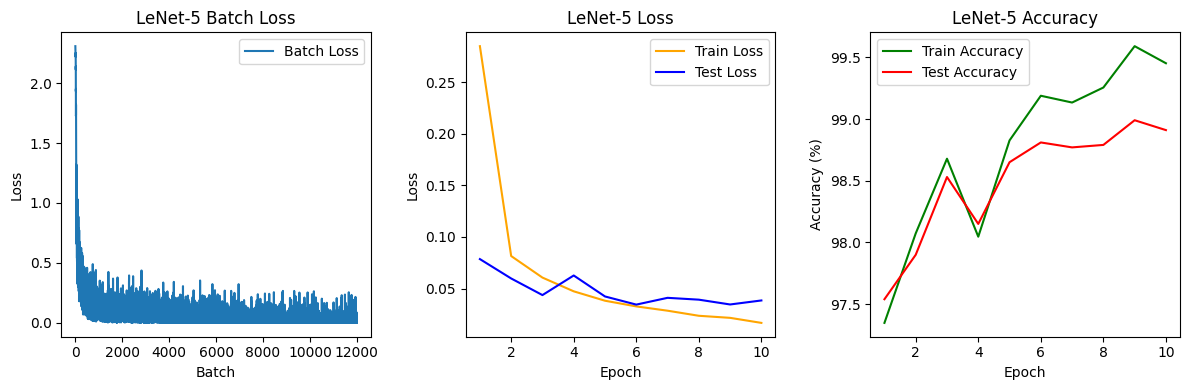

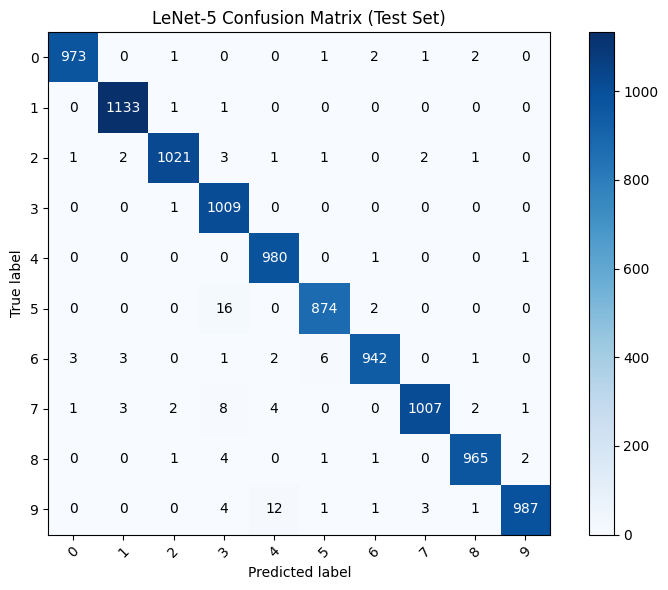

LeNet-5 Training accuracy: 99.45%
LeNet-5 Test accuracy: 98.91%


In [ ]:
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x


model = LeNet5().to(device)
print(model)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

batch_losses = []
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

def accuracy(loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for data, labels in loader:
            data, labels = data.to(device), labels.to(device)
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

def evaluate(loader):
    model.eval()
    running = 0.0
    with torch.no_grad():
        for data, labels in loader:
            data, labels = data.to(device), labels.to(device)
            outputs = model(data)
            loss = criterion(outputs, labels)
            running += loss.item()
    return running / len(loader)

epochs = 10
for epoch in range(epochs):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        batch_losses.append(loss.item())

    avg_loss = running_loss / len(trainloader)
    train_losses.append(avg_loss)
    test_losses.append(evaluate(testloader))

    train_acc = accuracy(trainloader)
    test_acc = accuracy(testloader)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"Epoch {epoch + 1}/{epochs} | Loss: {avg_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")


plt.figure(figsize = (12, 4))

plt.subplot(1, 3, 1)
plt.plot(batch_losses, label = 'Batch Loss')
plt.title('LeNet-5 Batch Loss')
plt.xlabel('Batch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(range(1, epochs + 1), train_losses, label = 'Train Loss', color = 'orange')
plt.plot(range(1, epochs + 1), test_losses, label = 'Test Loss', color = 'blue')
plt.title('LeNet-5 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(range(1, epochs + 1), train_accuracies, label = 'Train Accuracy', color = 'green')
plt.plot(range(1, epochs + 1), test_accuracies, label = 'Test Accuracy', color = 'red')
plt.title('LeNet-5 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()


all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for data, labels in testloader:
        data, labels = data.to(device), labels.to(device)
        outputs = model(data)
        _, predicted = torch.max(outputs.data, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize = (8, 6))
plt.imshow(cm, interpolation = 'nearest', cmap = plt.cm.Blues)
plt.title('LeNet-5 Confusion Matrix (Test Set)')
plt.colorbar()
tick_marks = np.arange(10)
plt.xticks(tick_marks, classes, rotation = 45)
plt.yticks(tick_marks, classes)
plt.ylabel('True label')
plt.xlabel('Predicted label')

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'), ha = 'center', va = 'center',
                 color = 'white' if cm[i, j] > thresh else 'black')

plt.tight_layout()
plt.show()

print(f"LeNet-5 Training accuracy: {train_accuracies[-1]:.2f}%")
print(f"LeNet-5 Test accuracy: {test_accuracies[-1]:.2f}%")


### (b) Modern Small CNN (3 conv layers with batch normalization and dropout)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=1024, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inp

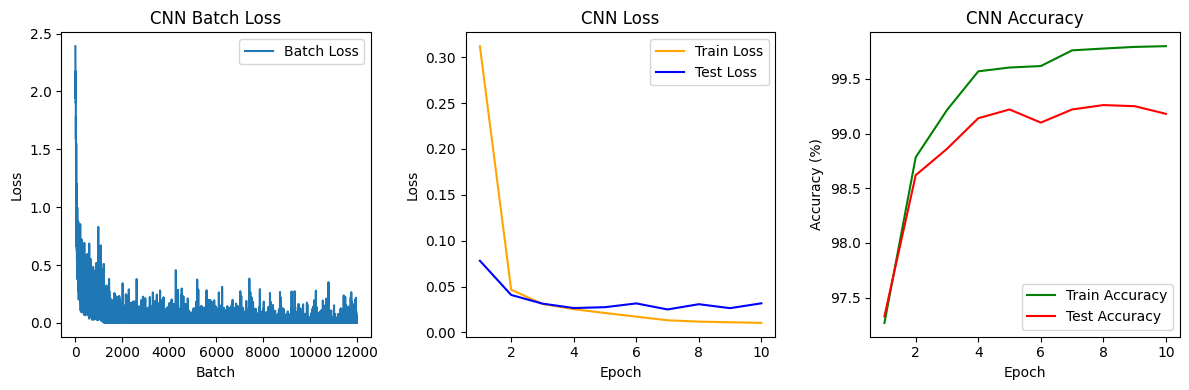

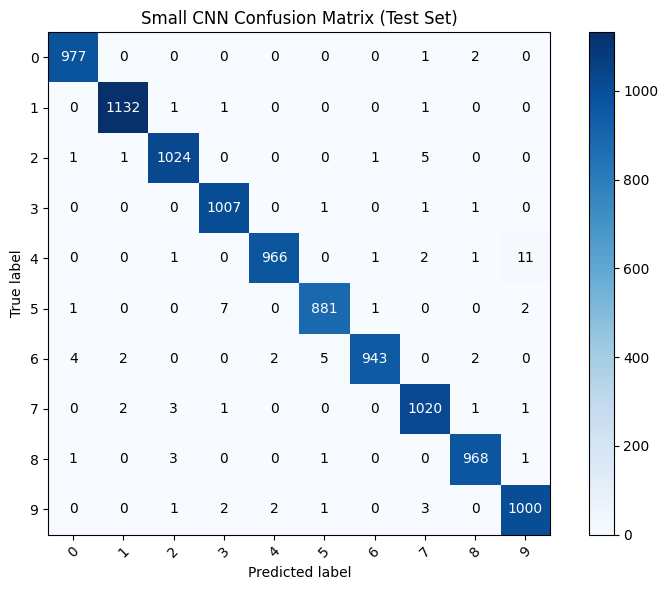

Small CNN Training accuracy: 99.80%
Small CNN Test accuracy: 99.18%


In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding = 1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, 3, padding = 1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 64, 3, padding = 1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(-1, 64 * 4 * 4)
        x = self.classifier(x)
        return x


model = CNN().to(device)
print(model)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

batch_losses = []
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

def accuracy(loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for data, labels in loader:
            data, labels = data.to(device), labels.to(device)
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

def evaluate(loader):
    model.eval()
    running = 0.0
    with torch.no_grad():
        for data, labels in loader:
            data, labels = data.to(device), labels.to(device)
            outputs = model(data)
            loss = criterion(outputs, labels)
            running += loss.item()
    return running / len(loader)

epochs = 10
for epoch in range(epochs):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        batch_losses.append(loss.item())

    avg_loss = running_loss / len(trainloader)
    train_losses.append(avg_loss)
    test_losses.append(evaluate(testloader))

    train_acc = accuracy(trainloader)
    test_acc = accuracy(testloader)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"Epoch {epoch + 1}/{epochs} | Loss: {avg_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")


plt.figure(figsize = (12, 4))

plt.subplot(1, 3, 1)
plt.plot(batch_losses, label = 'Batch Loss')
plt.title('CNN Batch Loss')
plt.xlabel('Batch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(range(1, epochs + 1), train_losses, label = 'Train Loss', color = 'orange')
plt.plot(range(1, epochs + 1), test_losses, label = 'Test Loss', color = 'blue')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(range(1, epochs + 1), train_accuracies, label = 'Train Accuracy', color = 'green')
plt.plot(range(1, epochs + 1), test_accuracies, label = 'Test Accuracy', color = 'red')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()


all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for data, labels in testloader:
        data, labels = data.to(device), labels.to(device)
        outputs = model(data)
        _, predicted = torch.max(outputs.data, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize = (8, 6))
plt.imshow(cm, interpolation = 'nearest', cmap = plt.cm.Blues)
plt.title('Small CNN Confusion Matrix (Test Set)')
plt.colorbar()
tick_marks = np.arange(10)
plt.xticks(tick_marks, classes, rotation = 45)
plt.yticks(tick_marks, classes)
plt.ylabel('True label')
plt.xlabel('Predicted label')

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'), ha = 'center', va = 'center',
                 color = 'white' if cm[i, j] > thresh else 'black')

plt.tight_layout()
plt.show()

print(f"Small CNN Training accuracy: {train_accuracies[-1]:.2f}%")
print(f"Small CNN Test accuracy: {test_accuracies[-1]:.2f}%")


## Question 3: Transfer Learning with ResNet18 on Hymenoptera Dataset

In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import numpy as np
import time
import os


data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

batch_size = 8

data_dir = './data/hymenoptera_data'

image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size = batch_size, shuffle = True, num_workers = 0) for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
print(f"Classes: {class_names}")
print(f"Train images: {dataset_sizes['train']}, Val images: {dataset_sizes['val']}")


Using device: cuda
Classes: ['ants', 'bees']
Train images: 244, Val images: 153


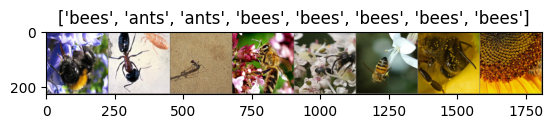

In [6]:
def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)


inputs, labels = next(iter(dataloaders['train']))
out = torchvision.utils.make_grid(inputs)
imshow(out, title=[class_names[x] for x in labels])
plt.show()


def train_model(model, criterion, optimizer, scheduler, num_epochs = 15):
    since = time.time()

    best_model_params_path = 'best_model_params.pt'
    torch.save(model.state_dict(), best_model_params_path)
    best_acc = 0.0

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f'Epoch {epoch + 1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item() * 100)

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                torch.save(model.state_dict(), best_model_params_path)

        print()

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:4f}')

    model.load_state_dict(torch.load(best_model_params_path, weights_only=True))
    return model, history


def plot_history(history, title):
    epochs_range = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize = (12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label = 'Train Loss', color = 'orange')
    plt.plot(epochs_range, history['val_loss'], label = 'Val Loss', color = 'blue')
    plt.title(f'{title} Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history['train_acc'], label = 'Train Accuracy', color = 'green')
    plt.plot(epochs_range, history['val_acc'], label = 'Val Accuracy', color = 'red')
    plt.title(f'{title} Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()

    plt.tight_layout()
    plt.show()


### (a) Fine-tuning the ConvNet

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 173MB/s]


Epoch 1/15
----------
train Loss: 0.4940 Acc: 0.7172
val Loss: 0.2900 Acc: 0.8758

Epoch 2/15
----------
train Loss: 0.3111 Acc: 0.8566
val Loss: 0.1730 Acc: 0.9346

Epoch 3/15
----------
train Loss: 0.2517 Acc: 0.8852
val Loss: 0.1473 Acc: 0.9412

Epoch 4/15
----------
train Loss: 0.2671 Acc: 0.8934
val Loss: 0.2492 Acc: 0.9085

Epoch 5/15
----------
train Loss: 0.2364 Acc: 0.8975
val Loss: 0.1905 Acc: 0.9412

Epoch 6/15
----------
train Loss: 0.1231 Acc: 0.9631
val Loss: 0.2172 Acc: 0.9020

Epoch 7/15
----------
train Loss: 0.1552 Acc: 0.9426
val Loss: 0.1675 Acc: 0.9608

Epoch 8/15
----------
train Loss: 0.1321 Acc: 0.9467
val Loss: 0.1583 Acc: 0.9608

Epoch 9/15
----------
train Loss: 0.1141 Acc: 0.9713
val Loss: 0.1679 Acc: 0.9608

Epoch 10/15
----------
train Loss: 0.1839 Acc: 0.9303
val Loss: 0.1641 Acc: 0.9608

Epoch 11/15
----------
train Loss: 0.1479 Acc: 0.9508
val Loss: 0.1710 Acc: 0.9477

Epoch 12/15
----------
train Loss: 0.1197 Acc: 0.9508
val Loss: 0.1699 Acc: 0.9608

E

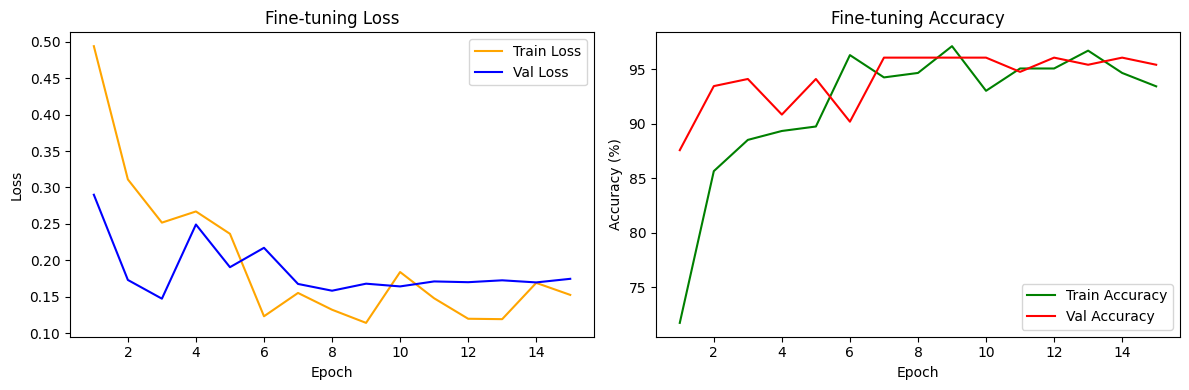

Fine-tuning Training accuracy: 93.44%
Fine-tuning Validation accuracy: 95.42%


In [7]:
model_ft = models.resnet18(weights = models.ResNet18_Weights.IMAGENET1K_V1)
num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, len(class_names))

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_ft = optim.SGD(model_ft.parameters(), lr = 0.001, momentum = 0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size = 7, gamma = 0.1)

model_ft, history_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler, num_epochs = 15)

plot_history(history_ft, 'Fine-tuning')

print(f"Fine-tuning Training accuracy: {history_ft['train_acc'][-1]:.2f}%")
print(f"Fine-tuning Validation accuracy: {history_ft['val_acc'][-1]:.2f}%")


### (b) ConvNet as fixed feature extractor

Epoch 1/15
----------
train Loss: 0.6369 Acc: 0.6516
val Loss: 0.3040 Acc: 0.9085

Epoch 2/15
----------
train Loss: 0.4410 Acc: 0.7951
val Loss: 0.4155 Acc: 0.8366

Epoch 3/15
----------
train Loss: 0.3630 Acc: 0.8361
val Loss: 0.1825 Acc: 0.9412

Epoch 4/15
----------
train Loss: 0.3635 Acc: 0.8238
val Loss: 0.2528 Acc: 0.8954

Epoch 5/15
----------
train Loss: 0.3183 Acc: 0.8566
val Loss: 0.1975 Acc: 0.9412

Epoch 6/15
----------
train Loss: 0.2890 Acc: 0.8566
val Loss: 0.1761 Acc: 0.9346

Epoch 7/15
----------
train Loss: 0.3262 Acc: 0.8648
val Loss: 0.1685 Acc: 0.9346

Epoch 8/15
----------
train Loss: 0.3166 Acc: 0.8566
val Loss: 0.1776 Acc: 0.9412

Epoch 9/15
----------
train Loss: 0.2653 Acc: 0.8975
val Loss: 0.1694 Acc: 0.9542

Epoch 10/15
----------
train Loss: 0.2277 Acc: 0.9139
val Loss: 0.1698 Acc: 0.9477

Epoch 11/15
----------
train Loss: 0.2108 Acc: 0.9344
val Loss: 0.1787 Acc: 0.9477

Epoch 12/15
----------
train Loss: 0.2087 Acc: 0.9344
val Loss: 0.1731 Acc: 0.9346

E

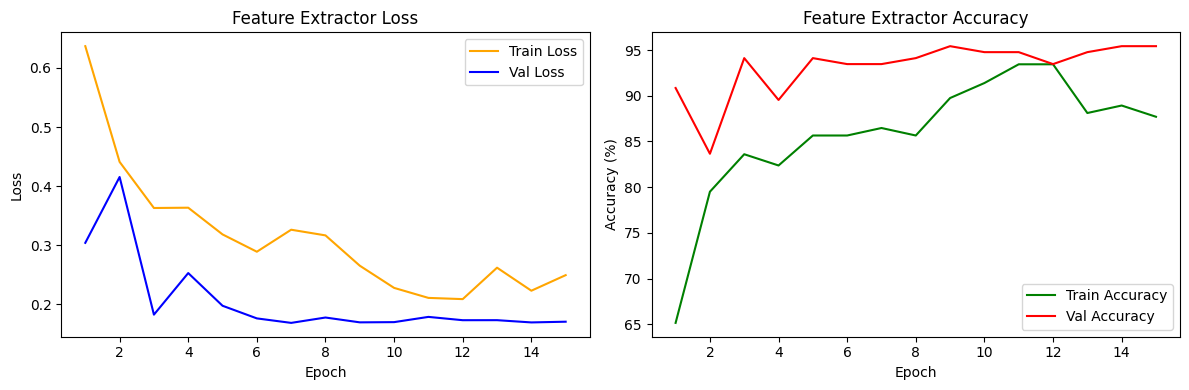

Feature Extractor Training accuracy: 87.70%
Feature Extractor Validation accuracy: 95.42%


In [8]:
model_conv = models.resnet18(weights = models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_conv.parameters():
    param.requires_grad = False

num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, len(class_names))

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr = 0.001, momentum = 0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size = 7, gamma = 0.1)

model_conv, history_fe = train_model(model_conv, criterion, optimizer_conv, exp_lr_scheduler, num_epochs = 15)

plot_history(history_fe, 'Feature Extractor')

print(f"Feature Extractor Training accuracy: {history_fe['train_acc'][-1]:.2f}%")
print(f"Feature Extractor Validation accuracy: {history_fe['val_acc'][-1]:.2f}%")
